# 0. How to change the map: a guide to the parameters

A FlowMapper project has **data** (nodes, flows, region polygons, a region attribute table) and
**settings blocks**, one per panel of FlowMapper.org. In Python each block is a dictionary on the
project. The keys are exactly the ones in the project file, so a map styled here opens unchanged on
FlowMapper.org (File > Project > Load Project).

| Python attribute | FlowMapper.org panel | project-file key |
|---|---|---|
| `p.flow_settings` | Flows tab | `flowMapFileSettings` |
| `p.node_settings` | Nodes tab | `pointMapFileSettings` |
| `p.region_settings` | Regions tab (symbology) | `selfDesignedBaseMapSettings` |
| `p.region_join` | Regions tab (join fields) | `choroplethMapSettings` |
| `p.basemap_settings` | Base map, projection, title, north arrow | `onlineBaseMapSettings` |
| `p.view_settings` | View menu (dark mode, drawing order, legends) | `viewSettings` |

Change a value with `p.flow_settings["numTopFlows"] = 50`, or several at once with
`p.flow_settings.update(numTopFlows=50, widthMax=20)`. Then draw the map with
`p.render(...)` / `p.save_map(...)`, or save the project with `p.save(...)`.

This notebook goes through the settings one panel at a time, each time drawing the same map with
different values. Run a cell, change a value, run it again.

### Setup

Imports, the data folder, and a few helpers used below: `figure_ground()` (the high-contrast look),
`size_nodes_by_total_flow()`, `show()` / `map_image()` / `show_grid()` (draw maps) and
`compare_settings()` (draw the same map with different settings side by side).

In [1]:
%matplotlib inline
import io
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import flowmapper_org as fm

# Example data of the FlowMapper GitHub repository (folder "Data"): FLOWMAPPER_DATA, else the
# repository these notebooks live in (python/notebooks -> ../../Data), else a local clone.
_candidates = [os.environ.get("FLOWMAPPER_DATA"), Path.cwd().parent.parent / "Data", r"D:\GitHub\flowmapper\Data"]
DATA = next((Path(c) for c in _candidates if c and Path(c).is_dir()), None)
assert DATA is not None, ("FlowMapper example data not found: clone https://github.com/geo-social/flowmapper "
                          "and set FLOWMAPPER_DATA to its Data folder")
OUT = Path("output")
OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("flowmapper.org", fm.__version__, "- mirrors FlowMapper.org", fm.FLOWMAPPER_WEB_VERSION)

# ---------------------------------------------------------------------------------------------
# The look used in these notebooks: figure-ground contrast.
#   * flows are the figure: Tapered Fading Arc (TAF), dark colour ramps, full opacity;
#   * regions are the ground: their colours are kept but drawn pale (35 % opacity);
#   * nodes are drawn on top of the flows, dark grey with a white outline.
# figure_ground() only sets ordinary FlowMapper settings, so the projects still open on
# FlowMapper.org. CONTRAST holds two Python-only drawing options (never saved in the file):
#   flow_contrast - raises the opacity of the fading arcs, so small flows stay visible;
#   flow_halo     - a thin white casing that separates flows from the regions below.
# ---------------------------------------------------------------------------------------------
CONTRAST = dict(flow_contrast=0.5, flow_halo=("#ffffff", 0.7))

# Zoom extents (west, south, east, north), a drawing option: render(..., extent=...).
# The legend and title are kept outside the extent.
LOWER48 = (-125, 24, -66.5, 49.5)
EUROPE = (-12, 34, 58, 68)


def us_extent(p):
    """LOWER48 when most of the project's nodes are in the contiguous U.S., else None.

    Every U.S. map in these notebooks is zoomed to the lower 48 (not Alaska and Hawaii):
    map_image() / show() use this whenever no extent is given."""
    ns = p.node_settings
    xf, yf = ns.get("X"), ns.get("Y")
    if p.nodes is None or xf not in p.nodes.columns or yf not in p.nodes.columns:
        return None
    x = pd.to_numeric(p.nodes[xf], errors="coerce")
    y = pd.to_numeric(p.nodes[yf], errors="coerce")
    ok = x.notna() & y.notna()
    if not ok.any():
        return None
    w, s, e, n = LOWER48
    inside = (x[ok].between(w, e) & y[ok].between(s, n)).mean()
    return LOWER48 if inside >= 0.8 else None

# Dark ramps (light end, dark end). The light end is a mid-tone, so the smallest flows
# are still clearly visible; a ColorBrewer ramp such as "Blues" starts almost white.
FLOW_RAMPS = {
    "navy":   ("#4a6fa5", "#0b1f4b"),
    "orange": ("#f16913", "#7f2704"),
    "purple": ("#807dba", "#3f007d"),
    "teal":   ("#3a9e8f", "#00332b"),
}


def figure_ground(p, flows="navy", region_opacity=35, node_color="#3d3d3d"):
    """Pale regions, dark prominent flows, nodes on top (ordinary FlowMapper settings)."""
    lo, hi = FLOW_RAMPS[flows] if flows in FLOW_RAMPS else flows
    p.flow_settings.update(flowStyleName="TAF", clrScheme="Custom", minCustomColor=lo, maxCustomColor=hi,
                           fillOpacity=100)
    p.region_settings.update(fillOpacity=region_opacity, strokeColor="#9e9e9e", strokeWidth=0.4)
    p.node_settings.update(clrScheme="Custom", minCustomColor=node_color, maxCustomColor=node_color,
                           noAttrFillColor=node_color, strokeColor="#ffffff", strokeWidth=0.8, fillOpacity=100)
    p.view_settings["drawingOrder"] = "nodes"          # nodes on top of flows
    return p


def size_nodes_by_total_flow(p, rmin=2, rmax=16, title="Total flow (in + out)", measure="__fm:grossflow"):
    """Circle size = gross flow (in-flow + out-flow), calculated from the flows.

    measure="__fm:inflow" sizes by flow received instead: better when one origin sends
    everything (refugees from one country), where the origin's total would dwarf the rest."""
    p.node_settings.update(ifMapAttribute=True, volume=measure, cfMethod="Proportional",
                           radiusMin=rmin, radiusMax=rmax, legendTitle=title)
    return p


_seen_notices = set()


def map_image(project, contrast=True, **render_options):
    """Draw a project at its own size and return the picture as an array.

    contrast=True adds the CONTRAST drawing options; False draws exactly as FlowMapper.org.
    Legends, title and scale bar are sized in screen pixels, so maps are drawn on their own
    and then tiled, rather than squeezed into small subplot axes."""
    opts = {**(CONTRAST if contrast else {}), **render_options}
    if "extent" not in opts and us_extent(project) is not None:
        opts["extent"] = LOWER48         # U.S. data: the lower 48, never Alaska and Hawaii
    r = project.render(**opts)       # with an extent, the title and legend are kept off the extent
    for n in r.notices:                     # FlowMapper's messages, each shown once
        if n not in _seen_notices:
            _seen_notices.add(n)
            print("notice:", n)
    buf = io.BytesIO()
    r.fig.savefig(buf, format="png")
    buf.seek(0)
    return plt.imread(buf)


def show(project, width=1000, height=700, contrast=True, **render_options):
    """Draw one map in the notebook."""
    show_grid([map_image(project, contrast, width=width, height=height, **render_options)], ncols=1,
              width=width / 70)


def show_grid(images, titles=None, ncols=3, width=22):
    """Tile pictures (arrays from map_image or plt.imread) in a grid."""
    nrows = -(-len(images) // ncols)
    h, w = images[0].shape[:2]
    fig, axes = plt.subplots(nrows, ncols, figsize=(width, width / ncols * h / w * nrows + 0.4 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, im, t in zip(axes.flat, images, titles or [""] * len(images)):
        ax.imshow(im)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()


def compare_settings(base, variants, ncols=3, width=900, height=600, **render_options):
    """Draw copies of `base`, each with some settings changed.

    variants = {"label": {"flow_settings": {...}, "node_settings": {...}, ...}, ...}"""
    images = []
    for label, change in variants.items():
        q = base.copy()
        for block, values in change.items():
            getattr(q, block).update(values)
        images.append(map_image(q, width=width, height=height, **render_options))
    show_grid(images, list(variants), ncols=ncols)

flowmapper.org 0.3.0 - mirrors FlowMapper.org 2.1


## The example map

Family-tree migration between U.S. states, 1887–1924 (Koylu et al., 2020): 49 state nodes, 2,326
flows and state polygons. `fm.Project.from_data` reads the same files you upload on FlowMapper.org
and guesses the ID, coordinate, origin, destination and volume fields as the web site does.

In [2]:
F = DATA / "FamilyTree"
base = fm.Project.from_data(
    F / "nodes_states_1789_1924.csv",                     # nodes: id + longitude/latitude
    F / "flows_1887_1924.csv",                            # flows: origin, destination, volume
    regions=F / "regions_states_latlon(base map input).json",
    region_table=F / "nodes_states_1789_1924.csv",        # values to colour the regions by
    name="Family-tree migration 1887-1924")
print(base)
print("node fields:", {k: base.node_settings[k] for k in ("id", "X", "Y")})
print("flow fields:", {k: base.flow_settings[k] for k in ("origin", "destination", "volume")})

<Project 'Family-tree migration 1887-1924': 49 regions, 49 nodes, 2326 flows>
node fields: {'id': 'rootsid', 'X': 'x', 'Y': 'y'}
flow fields: {'origin': 'orgState', 'destination': 'destState', 'volume': 'flows'}


Every setting starts at FlowMapper.org's default. With defaults the regions are not coloured yet,
the flows are Tapered Fading Arcs in the default navy and the nodes are not sized. Below,
`contrast=False` draws exactly what FlowMapper.org would draw.

notice: 154 flows use node IDs that are not in the node file (or have no coordinates), e.g. 143, 102, 108, 115, 149, .... They are not drawn.


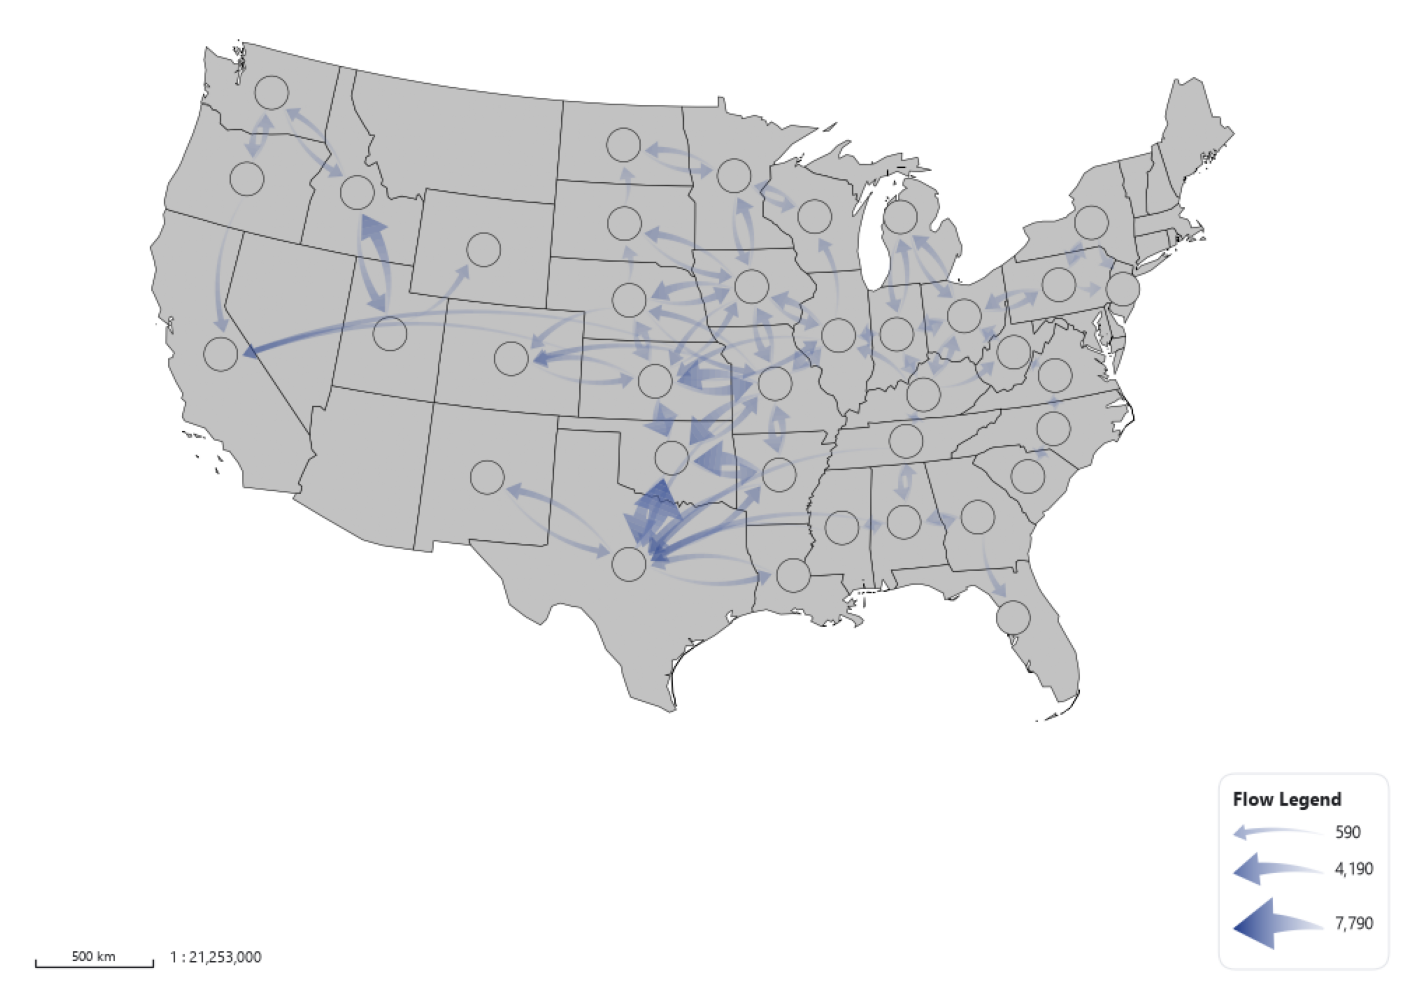

In [3]:
show(base, contrast=False)

### The look used in these notebooks

`figure_ground()` (defined in the setup cell, read it!) sets a handful of ordinary settings for
figure-ground contrast: dark flows at full opacity, pale regions, nodes on top with a white
outline. `size_nodes_by_total_flow()` sizes nodes by their total flow. The drawing options in
`CONTRAST` (`flow_contrast`, `flow_halo`) are added by `show()` unless `contrast=False`.

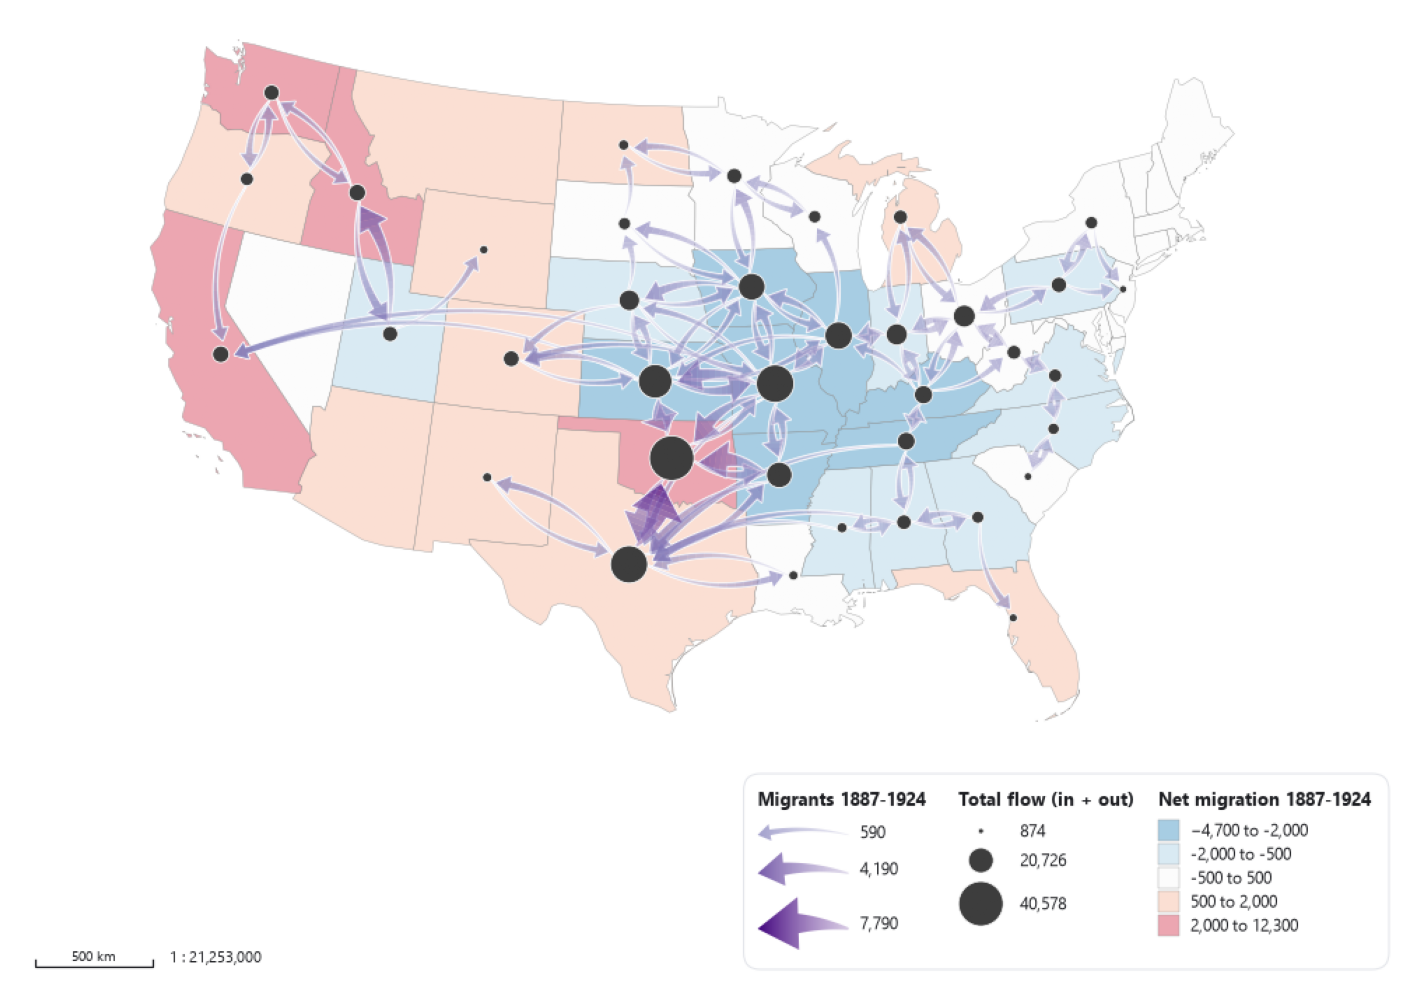

In [4]:
base.region_join.update(geoId="rootsid", CSVId="rootsid", value="Netflow_1887_1924")
base.region_settings.update(ifMapRegionAttribute=True, cfMethod="ManualBreak", clrScheme="RdBu", ifFlipColor=True,
                           clsNum=5, breakInput="-4700 -2000 -500 500 2000 12300",
                           legendTitle="Net migration 1887-1924")
base.flow_settings.update(numTopFlows=100, legendTitle="Migrants 1887-1924")
figure_ground(base, flows="purple")
size_nodes_by_total_flow(base)
show(base)

## 1. Flows (`p.flow_settings`)

| key | what it does | values |
|---|---|---|
| `origin`, `destination`, `volume` | the columns of the flow table | column names |
| `flowStyleName` | flow symbol | `"TAF"` Tapered Fading Arc (stored as `"nyt"`), `"CHA"` Curve Half Arrow (`"curve"`), `"SHA"` Straight Half Arrow (`"strtHfArw"`) |
| `numTopFlows` | *Show top flows*: only the largest N flows are drawn | 1–1000 |
| `cfMethod` | classification of flow volumes | `"Proportional"` (unclassed), `"Quantile"`, `"EqualInterval"`, `"NaturalBreak"`, `"ManualBreak"` |
| `clsNum` | number of classes | 2–9 |
| `breakInput` | manual breaks (with `ManualBreak`) | `"min b1 b2 ... max"` |
| `clrScheme` | colours | ColorBrewer name (`"Blues"`, `"OrRd"`...), `"Custom"`, `"Black"` (TAF navy), `"LinGrad"` (origin → destination) |
| `minCustomColor`, `maxCustomColor` | ends of a `"Custom"` ramp | `"#rrggbb"` |
| `originColor`, `destinationColor` | ends of `"LinGrad"` | `"#rrggbb"` |
| `ifFlipColor` | reverse the ramp | `True` / `False` |
| `widthMin`, `widthMax` | thinnest / thickest flow, px | numbers |
| `fillOpacity` | opacity, % | 0–100 |
| `strokeColor`, `strokeWidth` | outline (not used by TAF) | colour, px |
| `symbology` | shape: `curvature`, `bend`, `headLength`, `headWidth`, `bundle`, `bundleStrength` | dict |
| `isDisplayedAsAbs` | rank negative volumes by absolute value | `True` / `False` |
| `legendTitle`, `decimalPlaces` | legend text | text, integer |

### Flow style

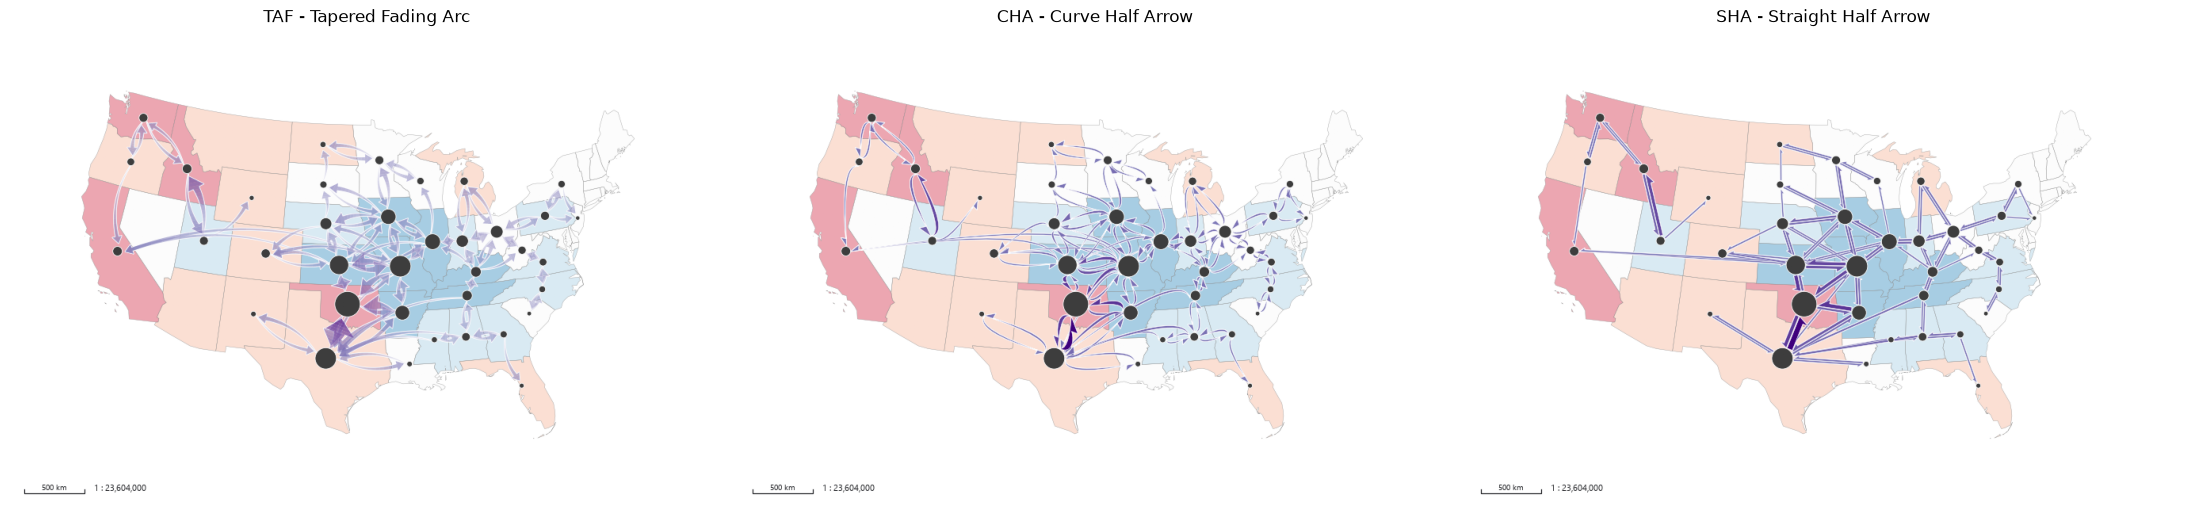

In [5]:
compare_settings(base, {
    "TAF - Tapered Fading Arc": {"flow_settings": {"flowStyleName": "TAF"}},
    "CHA - Curve Half Arrow":   {"flow_settings": {"flowStyleName": "CHA"}},
    "SHA - Straight Half Arrow": {"flow_settings": {"flowStyleName": "SHA"}},
}, legend=False)

### How many flows: `numTopFlows`

The most effective way to make a flow map readable is to show fewer flows.

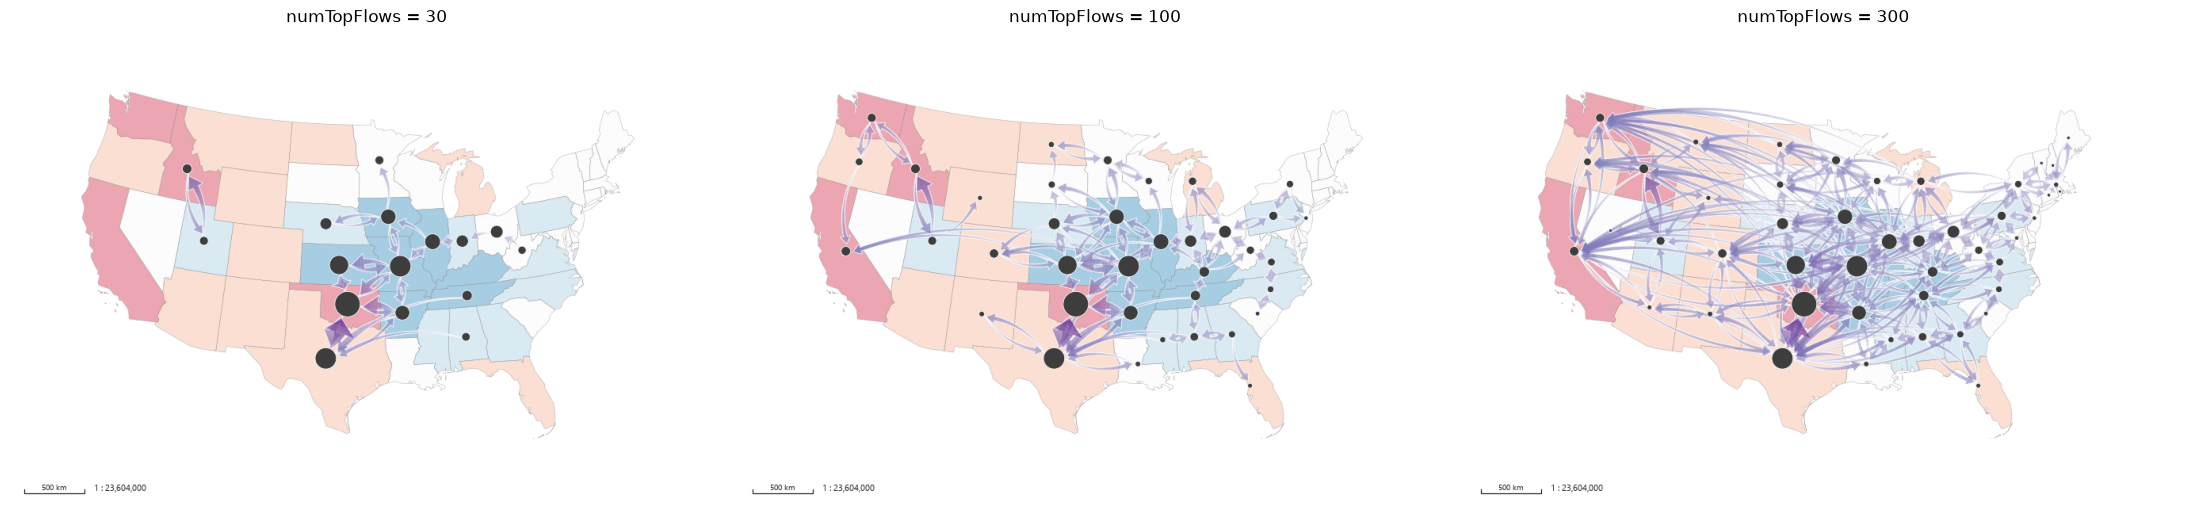

In [6]:
compare_settings(base, {f"numTopFlows = {n}": {"flow_settings": {"numTopFlows": n}} for n in (30, 100, 300)},
                 legend=False)

### Classification: `cfMethod`, `clsNum`, `breakInput`

Classes group flow volumes; each class gets one colour and one width.

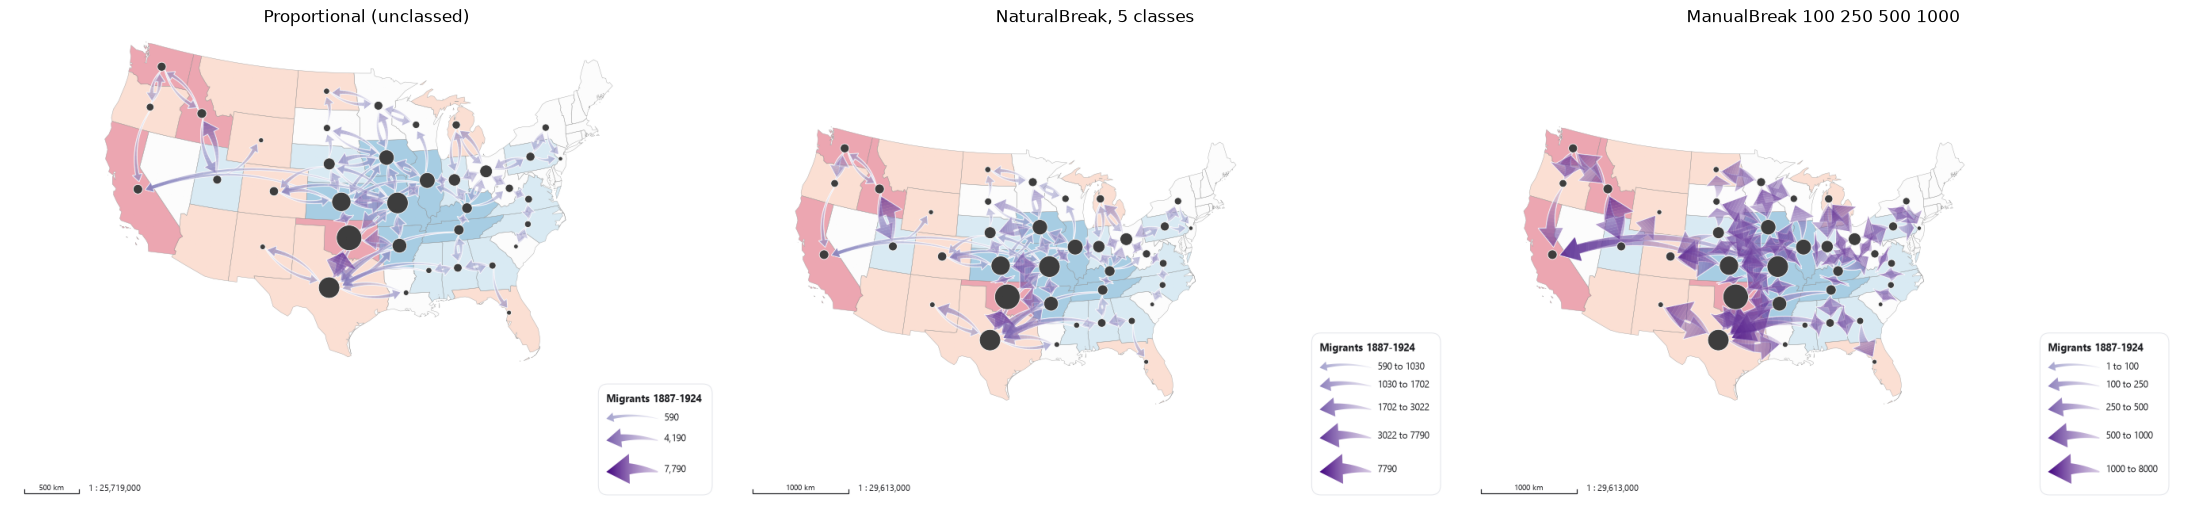

In [7]:
compare_settings(base, {
    "Proportional (unclassed)": {"flow_settings": {"cfMethod": "Proportional"}},
    "NaturalBreak, 5 classes": {"flow_settings": {"cfMethod": "NaturalBreak", "clsNum": 5}},
    "ManualBreak 100 250 500 1000": {"flow_settings": {"cfMethod": "ManualBreak", "breakInput": "1 100 250 500 1000 8000"}},
}, legend={"flows": True, "nodes": False, "regions": False})

### Colour: `clrScheme`, custom ramps, opacity

Light ColorBrewer ramps start almost white, so the smallest flows nearly disappear against pale
regions. A `"Custom"` ramp from a mid-tone to a dark colour keeps every flow visible.
`fillOpacity` below 100 makes flows fade into the regions.

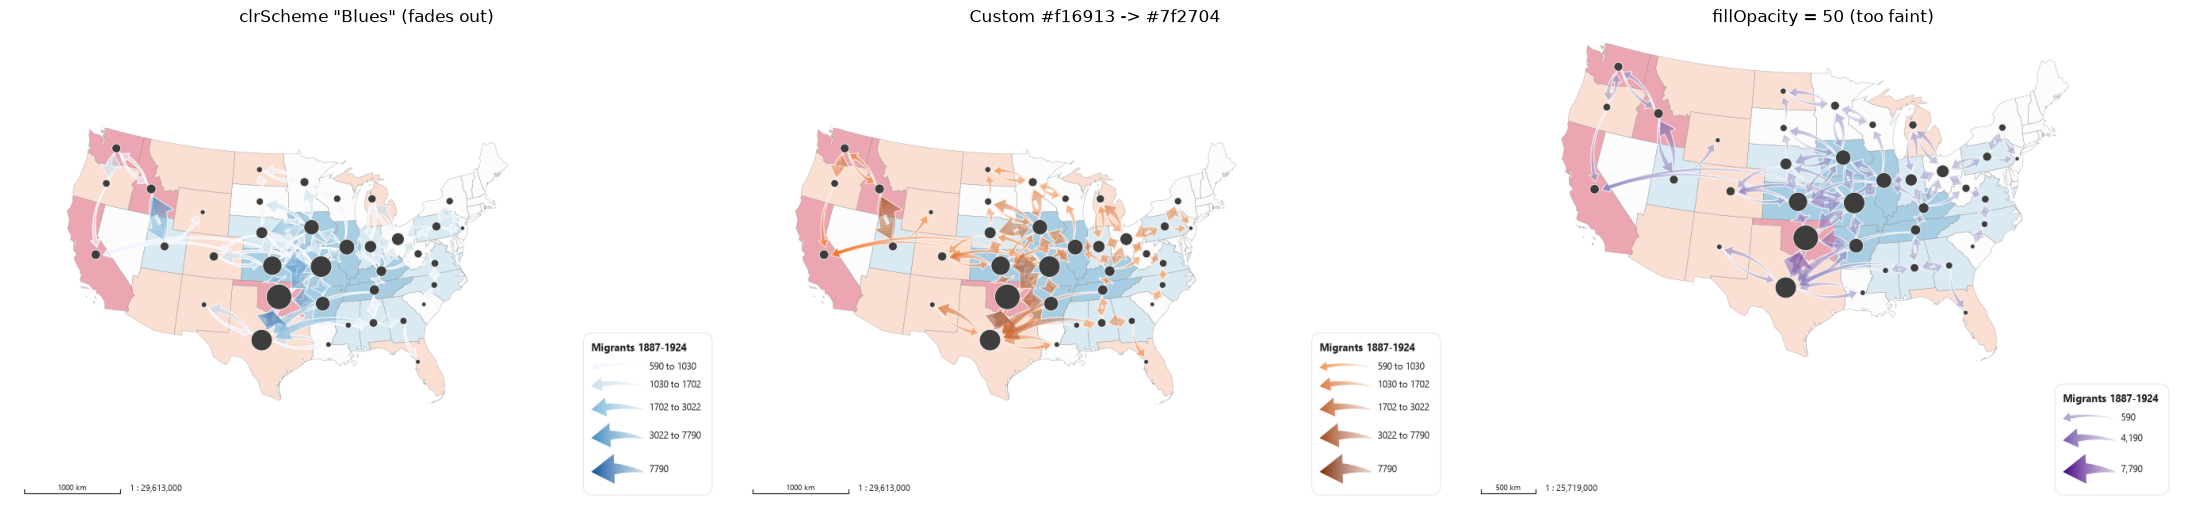

In [8]:
compare_settings(base, {
    'clrScheme "Blues" (fades out)': {"flow_settings": {"clrScheme": "Blues", "cfMethod": "NaturalBreak"}},
    'Custom #f16913 -> #7f2704': {"flow_settings": {"clrScheme": "Custom", "minCustomColor": "#f16913", "maxCustomColor": "#7f2704", "cfMethod": "NaturalBreak"}},
    'fillOpacity = 50 (too faint)': {"flow_settings": {"fillOpacity": 50}},
}, legend={"flows": True, "nodes": False, "regions": False})

### Width: `widthMin`, `widthMax`

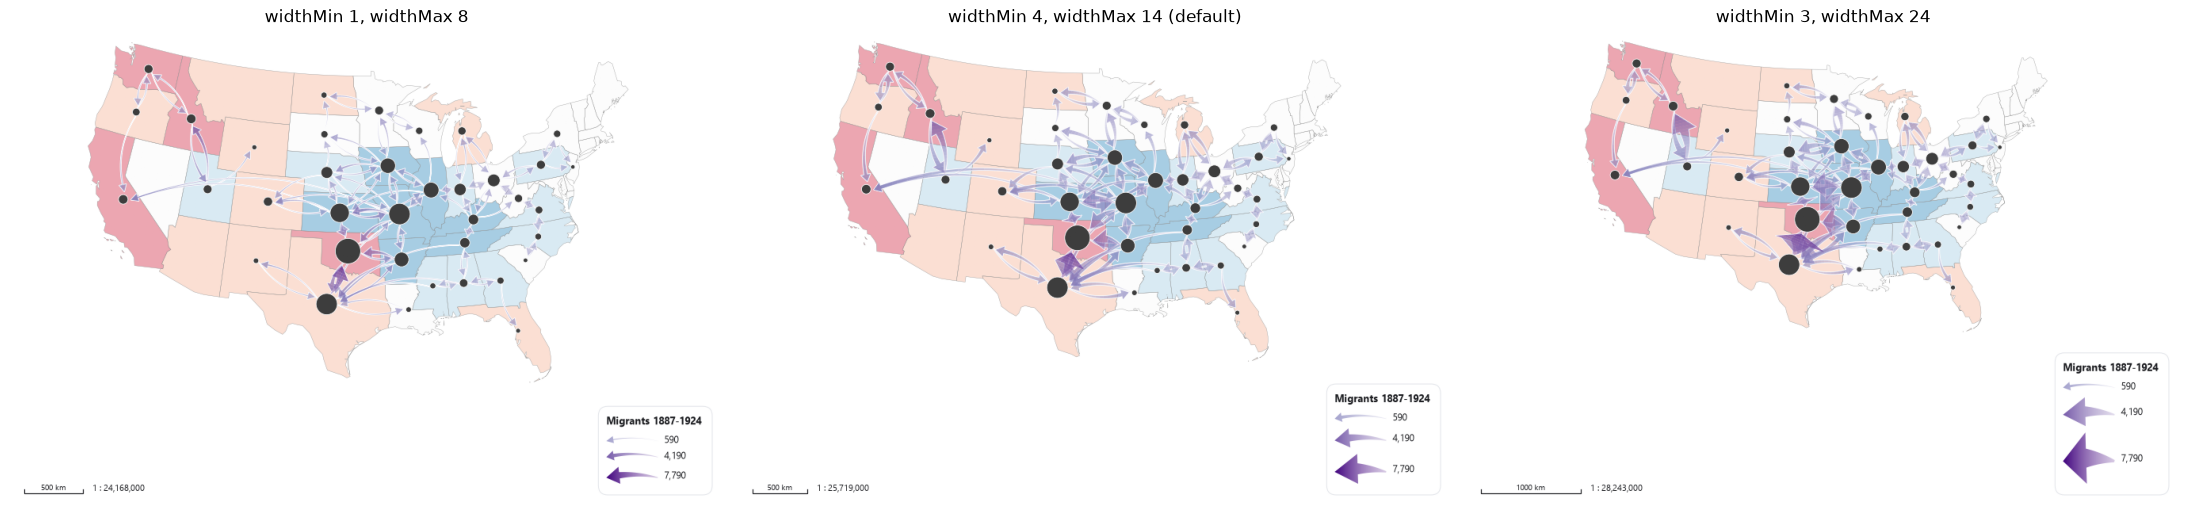

In [9]:
compare_settings(base, {
    "widthMin 1, widthMax 8": {"flow_settings": {"widthMin": 1, "widthMax": 8}},
    "widthMin 4, widthMax 14 (default)": {"flow_settings": {"widthMin": 4, "widthMax": 14}},
    "widthMin 3, widthMax 24": {"flow_settings": {"widthMin": 3, "widthMax": 24}},
}, legend={"flows": True, "nodes": False, "regions": False})

### Shape: `symbology`

`symbology` is a dictionary; change one entry and keep the others. `bundle` gathers flows with
similar directions (edge bundling, up to 1,500 flows).

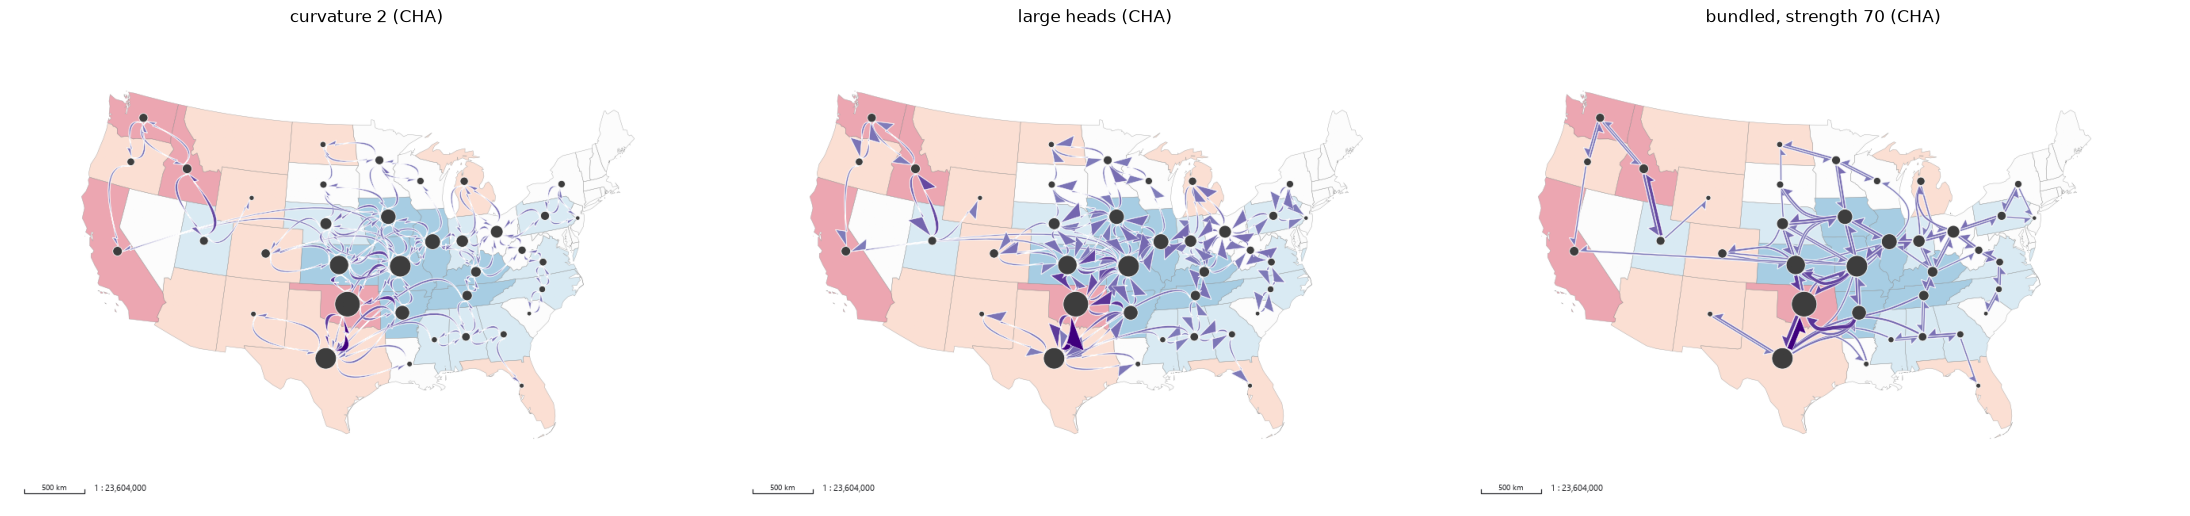

In [10]:
sym = base.flow_settings["symbology"]
compare_settings(base, {
    "curvature 2 (CHA)": {"flow_settings": {"flowStyleName": "CHA", "symbology": {**sym, "curvature": 2}}},
    "large heads (CHA)": {"flow_settings": {"flowStyleName": "CHA", "symbology": {**sym, "headLength": 2, "headWidth": 2}}},
    "bundled, strength 70 (CHA)": {"flow_settings": {"flowStyleName": "CHA", "symbology": {**sym, "bundle": True, "bundleStrength": 70}}},
}, legend=False)

## 2. Nodes (`p.node_settings`)

| key | what it does | values |
|---|---|---|
| `id`, `X`, `Y` | the columns of the node table (X = longitude, Y = latitude, WGS84) | column names |
| `ifMapAttribute` | size/colour nodes by a value | `True` / `False` |
| `volume` | the value: a node column, or a measure calculated from the flows | column name, `"__fm:inflow"`, `"__fm:outflow"`, `"__fm:grossflow"` (total), `"__fm:netflow"`, `"__fm:netflowratio"` |
| `cfMethod`, `clsNum`, `breakInput` | classification of node values | as for flows |
| `clrScheme`, `minCustomColor`, `maxCustomColor`, `ifFlipColor` | colours | as for flows |
| `radiusMin`, `radiusMax` | smallest / largest circle, px | numbers |
| `fillOpacity`, `strokeColor`, `strokeWidth` | fill opacity %, outline | |
| `noAttrFillColor`, `noAttrRadius` | nodes when `ifMapAttribute` is off | colour, px |
| `showNoFlowNodes` | also draw nodes without displayed flows | `True` / `False` |

Sizing nodes by **total flow** (`__fm:grossflow`) shows where movement concentrates. **Net flow**
(`__fm:netflow`, in − out) needs a diverging scheme. With an odd number of classes and breaks
symmetric around 0, the middle class is white, so nodes that gain and lose about equally stand
out from clear winners (blue) and losers (red). Circle size shows the absolute value.

symmetric breaks: -12300 -3100 -600 600 3100 12300


notice: __fm:netflow has negative values (minimum −4,619.00). Circle size shows the absolute value and circle color keeps the sign. A diverging color scheme such as Red-Blue or Purple-Green makes negative and positive values easy to tell apart.


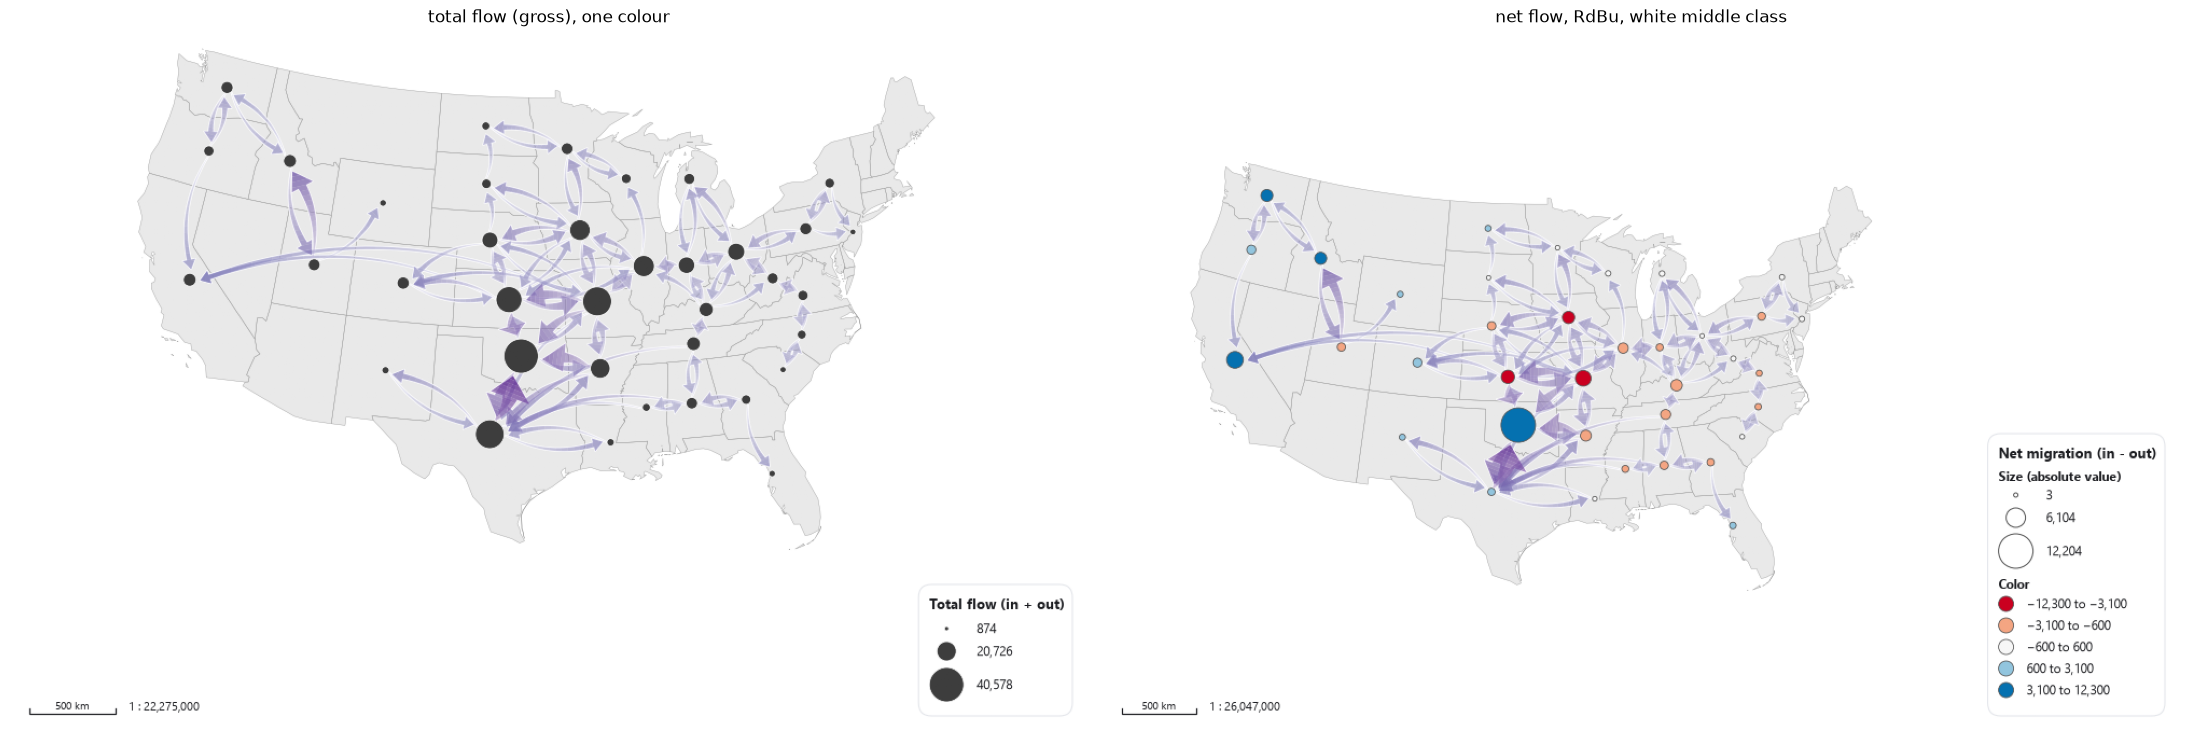

In [11]:
net = fm.node_measures(base.flows, "orgState", "destState", "flows")["netflow"]
M = float(np.ceil(net.abs().max() / 100) * 100)
a, b = round(M / 4, -2), round(M / 20, -2)
net_breaks = f"{-M:g} {-a:g} {-b:g} {b:g} {a:g} {M:g}"
print("symmetric breaks:", net_breaks)

plain = base.copy()
plain.region_settings["ifMapRegionAttribute"] = False      # plain regions: the nodes carry the net flow
compare_settings(plain, {
    "total flow (gross), one colour": {"node_settings": {"volume": "__fm:grossflow"}},
    "net flow, RdBu, white middle class": {"node_settings": {
        "volume": "__fm:netflow", "cfMethod": "ManualBreak", "clrScheme": "RdBu", "clsNum": 5,
        "breakInput": net_breaks, "strokeColor": "#555555", "legendTitle": "Net migration (in - out)"}},
}, ncols=2, width=1000, height=650, legend={"flows": False, "nodes": True, "regions": False})

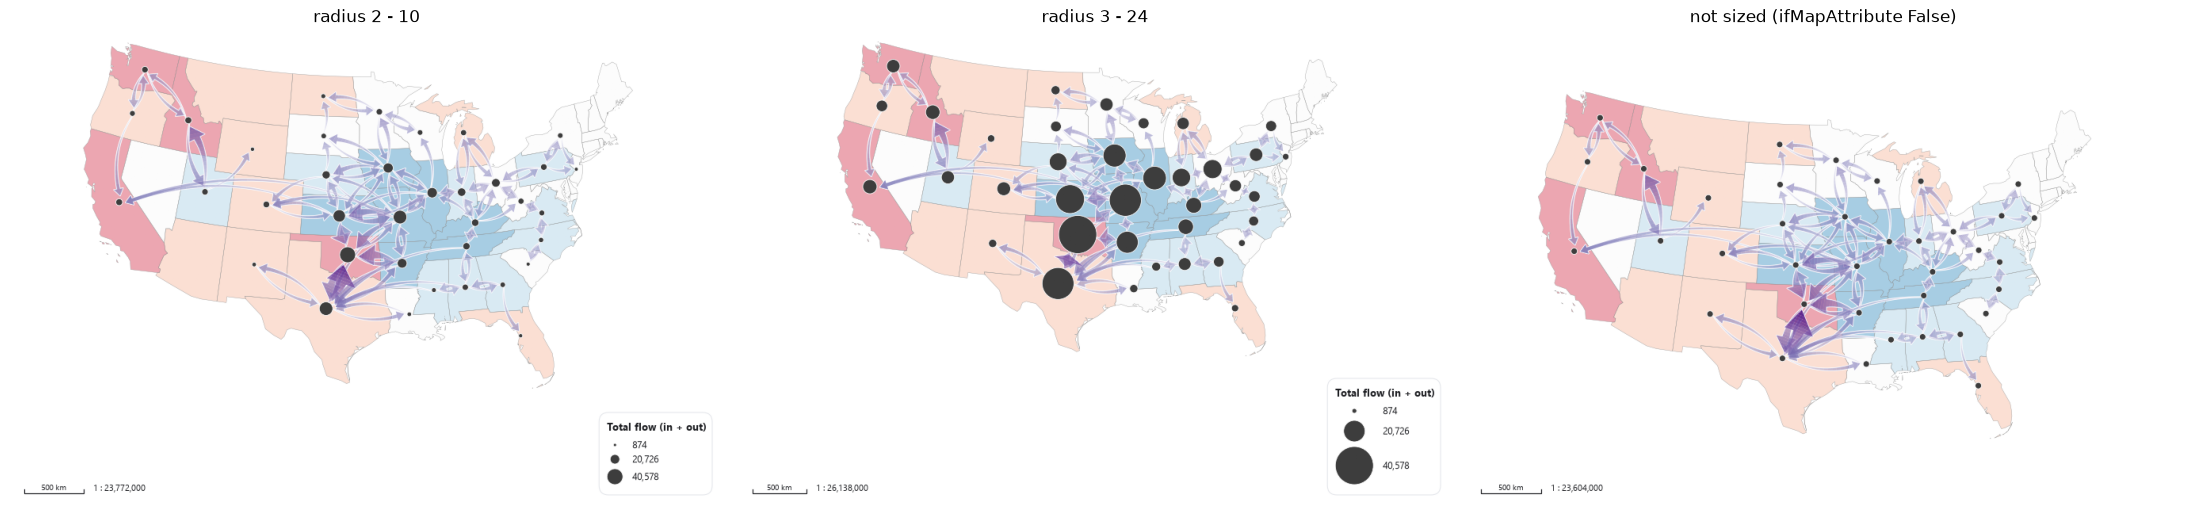

In [12]:
compare_settings(base, {
    "radius 2 - 10": {"node_settings": {"radiusMin": 2, "radiusMax": 10}},
    "radius 3 - 24": {"node_settings": {"radiusMin": 3, "radiusMax": 24}},
    "not sized (ifMapAttribute False)": {"node_settings": {"ifMapAttribute": False, "noAttrRadius": 4}},
}, legend={"flows": False, "nodes": True, "regions": False})

## 3. Regions (`p.region_join`, `p.region_settings`)

The region attribute table is joined to the polygons, like the Regions tab:

| `p.region_join` key | meaning |
|---|---|
| `geoId` | property of the polygons that identifies a region |
| `CSVId` | column of the region table with the same identifiers |
| `value` | column of the region table to map |

| `p.region_settings` key | what it does | values |
|---|---|---|
| `ifMapRegionAttribute` | colour regions by `value` | `True` / `False` |
| `cfMethod`, `clsNum`, `breakInput` | classification | as for flows (also `"Categorical"`) |
| `clrScheme`, `ifFlipColor`, custom colours | colours | |
| `fillOpacity` | opacity, %. Keep it low (25–45) so regions stay in the background | 0–100 |
| `strokeColor`, `strokeWidth` | borders | |
| `fillColorNoAttr`, `ifHideNull` | regions without a value | colour, `True`/`False` |

In [13]:
print("polygon properties:", list(base.regions["features"][0]["properties"]))

polygon properties: ['stateID', 'rootsid', '__fm_id']


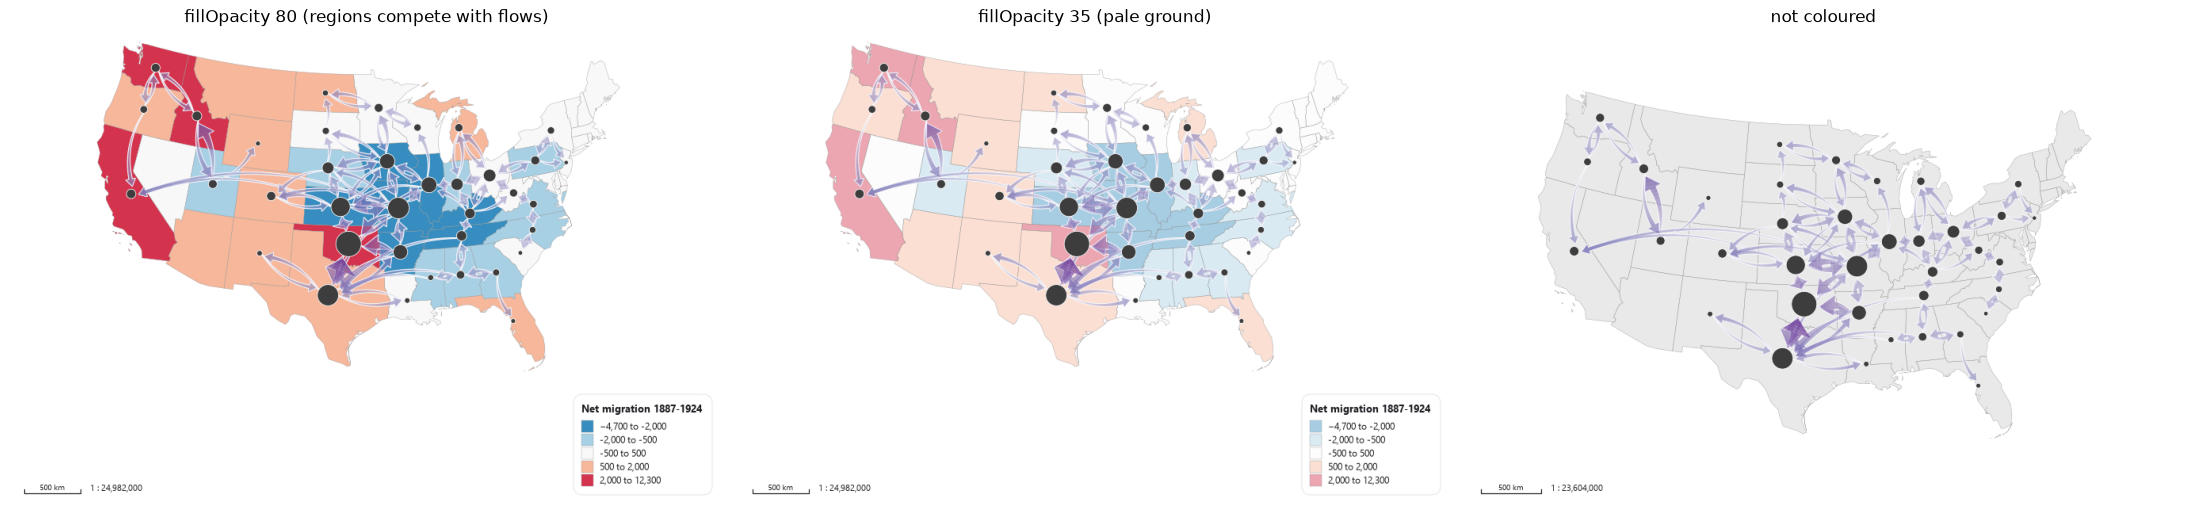

In [14]:
compare_settings(base, {
    "fillOpacity 80 (regions compete with flows)": {"region_settings": {"fillOpacity": 80}},
    "fillOpacity 35 (pale ground)": {"region_settings": {"fillOpacity": 35}},
    "not coloured": {"region_settings": {"ifMapRegionAttribute": False}},
}, legend={"flows": False, "nodes": False, "regions": True})

## 4. Map (`p.basemap_settings`, `p.view_settings`)

| key | what it does |
|---|---|
| `basemap_settings["projection"]` | map projection (`fm.projections.PROJECTION_GROUPS` lists them) |
| `ifAddTitle`, `title`, `titleSize`, `titleColor` | title |
| `ifAddDescription`, `description` | text below the map |
| `ifAddNorthArrow` | north arrow (`view_settings["northArrow"]` holds its style) |
| `ifAddProjectionLabel` | projection name in the corner |
| `baseMap`, `baseMapOpacity` | online base map (static maps draw tiles only with `basemap="auto"` and the `contextily` package) |
| `view_settings["drawingOrder"]` | `"nodes"`: nodes on top of flows; `"flows"`: flows on top |
| `view_settings["darkMode"]` | dark map |
| `view_settings["legendVisibility"]` | `{"flows": True, "nodes": True, "regions": True}` |

In [15]:
from flowmapper_org.projections import PROJECTION_GROUPS
PROJECTION_GROUPS

{'North America': ['abEqAreaUS', 'laeaNA', 'lccCanada', 'abEqAreaAk'],
 'Europe and Middle East': ['abEqAreaEu',
  'laeaEurope',
  'ukBNG',
  'lccTurkey',
  'abEqAreaME',
  'abEqAreaRu'],
 'Asia, Africa, Oceania, S. America': ['abEqAreaCn',
  'abEqAreaIn',
  'abEqAreaAfc',
  'abEqAreaAs',
  'abEqAreaSthAm'],
 'Polar': ['laeaArctic', 'psAntarctic'],
 'World': ['eqEarth', 'robin', 'moll', 'gall', 'webMct']}

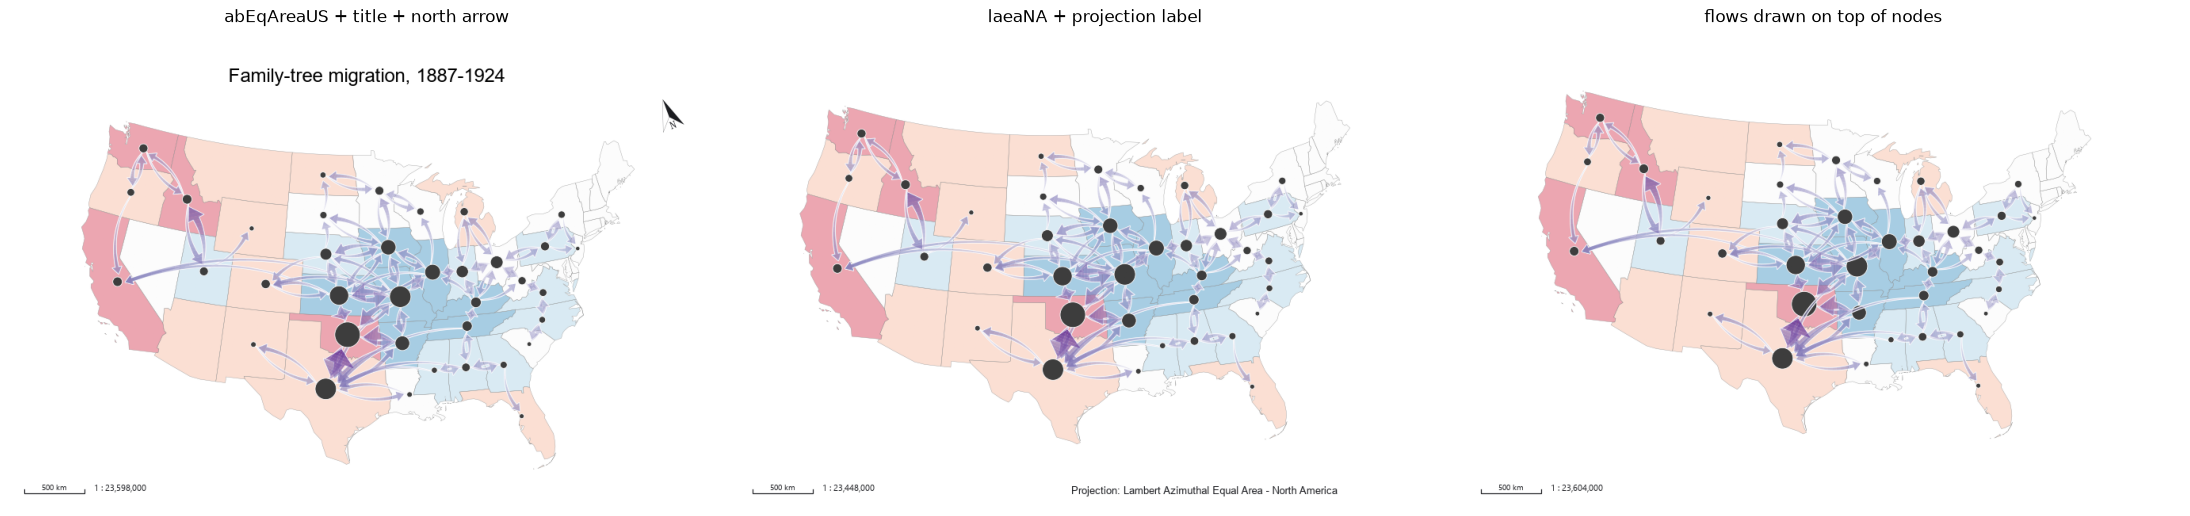

In [16]:
compare_settings(base, {
    "abEqAreaUS + title + north arrow": {"basemap_settings": {"projection": "abEqAreaUS", "ifAddTitle": True,
        "title": "Family-tree migration, 1887-1924", "titleSize": 24, "ifAddNorthArrow": True}},
    "laeaNA + projection label": {"basemap_settings": {"projection": "laeaNA", "ifAddProjectionLabel": True}},
    "flows drawn on top of nodes": {"view_settings": {"drawingOrder": "flows"}},
}, legend=False)

## 5. Drawing options (`p.render(...)`, `p.save_map(...)`)

These options change the picture only. They are never written to the project file.

| option | meaning |
|---|---|
| `width`, `height` | map size in screen pixels (as the browser window on FlowMapper.org) |
| `dpi` | resolution of saved images (96 = one pixel per screen pixel; 192 or 300 for print) |
| `projection` | draw in another projection without changing the project |
| `extent=(west, south, east, north)` | zoom to a lon/lat box |
| `legend` | `True`, `False` or `{"flows": .., "nodes": .., "regions": ..}` |
| `legend_loc` | `"lower right"` (FlowMapper), `"lower left"`, `"upper right"`, `"upper left"` |
| `title`, `north_arrow`, `projection_label`, `scale_bar` | override the project's choice |
| `dark` | dark mode |
| `basemap` | `"auto"` = the project's online base map (needs `contextily` and a connection) |
| `flow_contrast` | **Python only**: 0–1, makes Tapered Fading Arcs more opaque (default off = as FlowMapper.org) |
| `flow_halo` | **Python only**: white casing around flows: `True`, a colour, or `(colour, width_px)` |

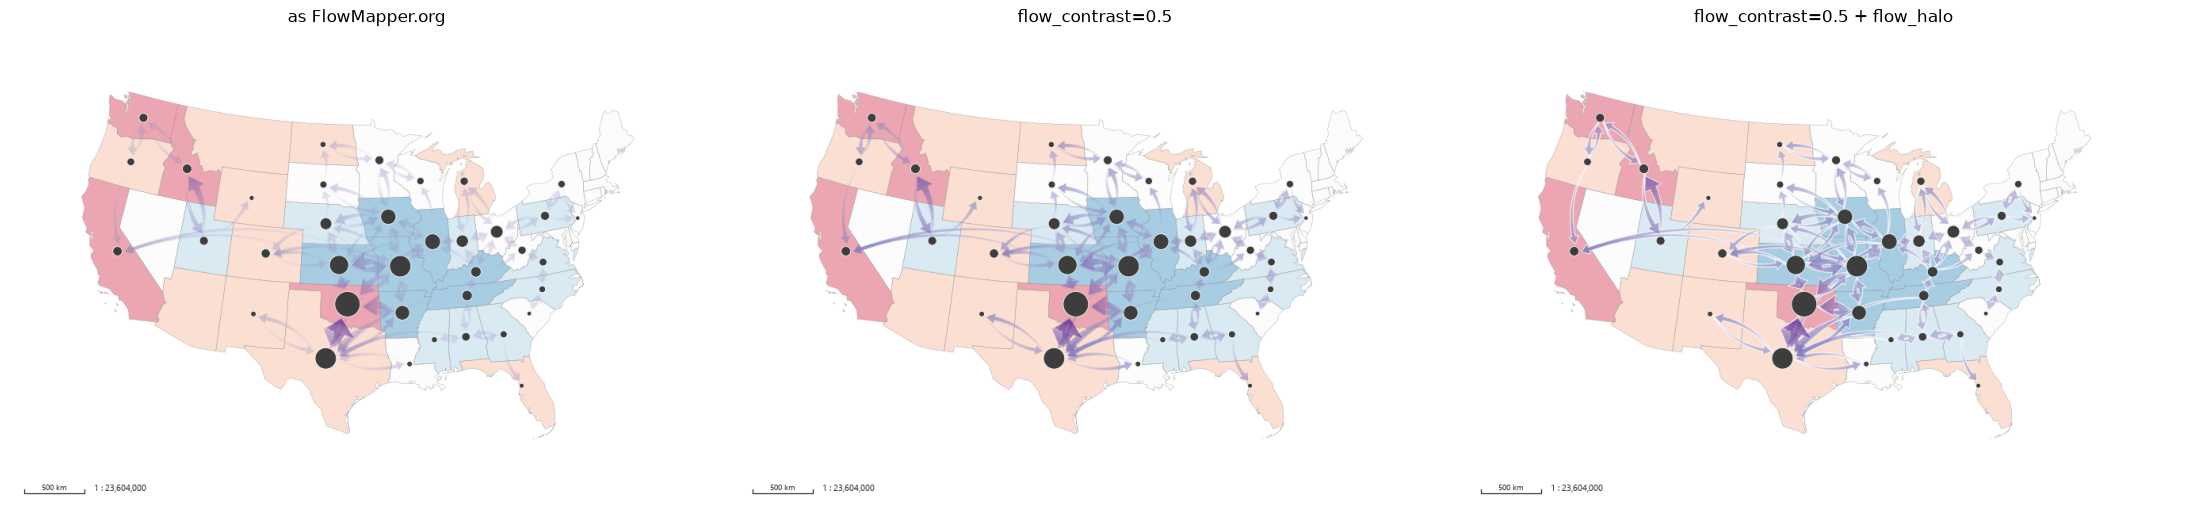

In [17]:
images = [map_image(base, contrast=False, width=900, height=600, legend=False),
          map_image(base, contrast=False, width=900, height=600, legend=False, flow_contrast=0.5),
          map_image(base, contrast=False, width=900, height=600, legend=False, flow_contrast=0.5, flow_halo=("#ffffff", 0.7))]
show_grid(images, ["as FlowMapper.org", "flow_contrast=0.5", "flow_contrast=0.5 + flow_halo"], ncols=3)

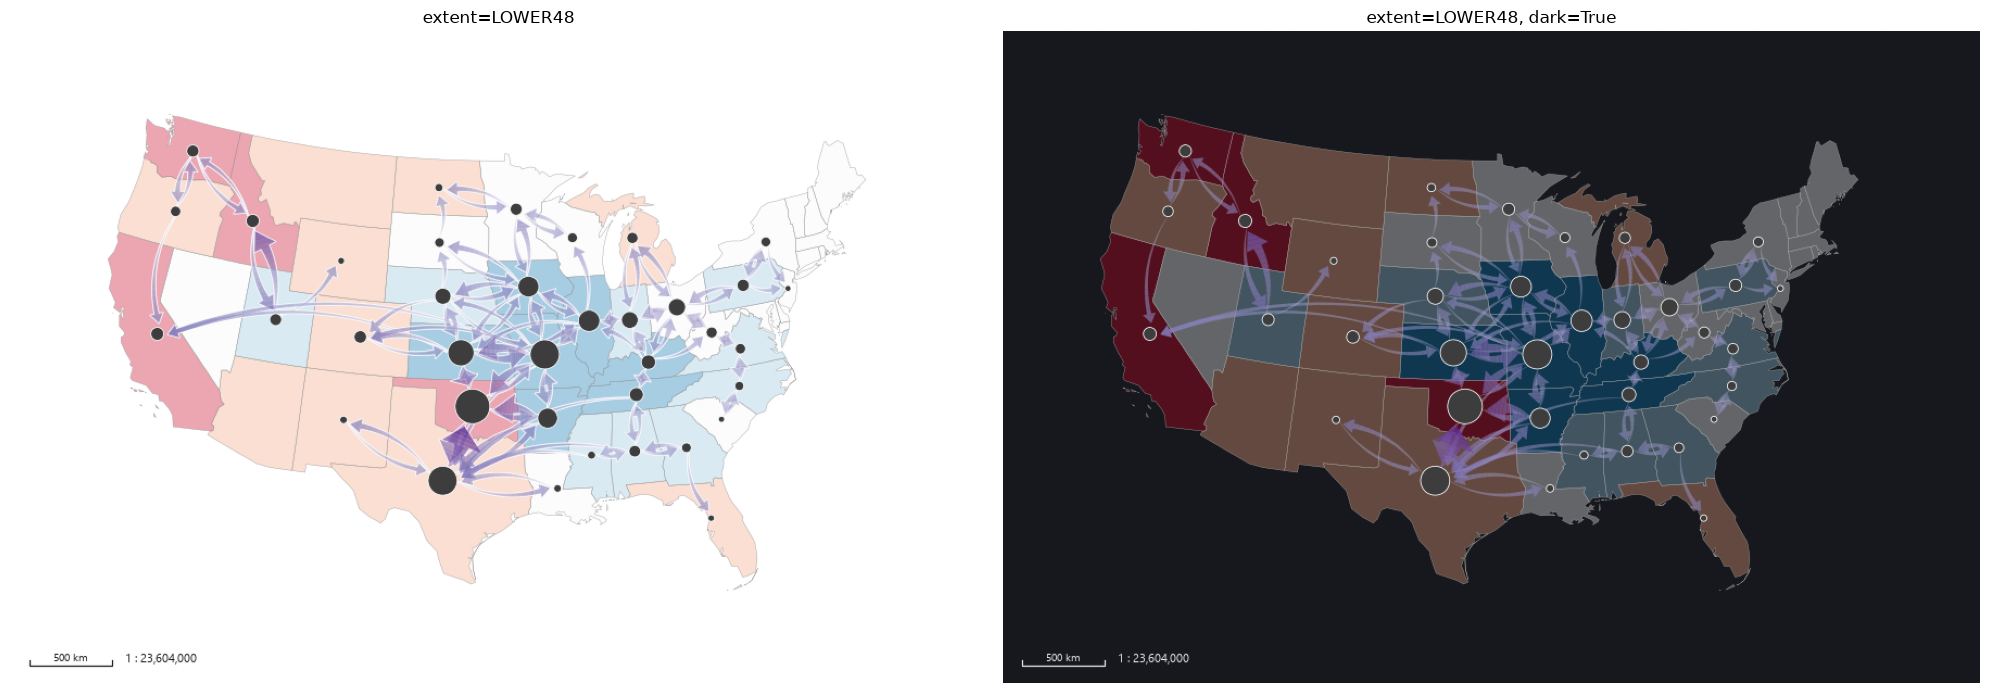

In [18]:
# extent=LOWER48 (set in the setup cell) keeps U.S. maps on the contiguous states, not Alaska and
# Hawaii; map_image()/show() apply it automatically to U.S. data (see us_extent in the setup cell).
show_grid([map_image(base, width=900, height=600, extent=LOWER48, legend=False),
           map_image(base, width=900, height=600, extent=LOWER48, dark=True, flow_halo=None, legend=False)],
          ["extent=LOWER48", "extent=LOWER48, dark=True"], ncols=2, width=20)

## 6. Save

* `p.save_map("map.png", width=..., height=..., dpi=192, extent=LOWER48, **CONTRAST)`: PNG, JPG,
  TIF, SVG or PDF (`save_map` does not add the extent by itself; pass it for U.S. maps);
* `p.save("project.json")`: open it on FlowMapper.org with File > Project > Load Project;
* `p.to_html("map.html")`: an interactive map in one HTML file.

In [19]:
base.save_map(OUT / "guide_map.png", width=1100, height=750, dpi=192, extent=LOWER48, **CONTRAST)
base.save_map(OUT / "guide_map.svg", width=1100, height=750, extent=LOWER48, **CONTRAST)
base.save(OUT / "guide_project.json")
print(sorted(p.name for p in OUT.glob("guide_*")))

['guide_map.png', 'guide_map.svg', 'guide_project.json']


## Reference: every setting and its default

The tables below list every key of each block with FlowMapper.org's default value.

In [20]:
from flowmapper_org.project import schema_defaults, BLOCK_ATTRS
for block, attr in BLOCK_ATTRS.items():
    d = schema_defaults(block)
    print(f"p.{attr}  ({block})")
    display(pd.DataFrame({"default": {k: repr(v) for k, v in d.items()}}))

p.basemap_settings  (onlineBaseMapSettings)


,default
baseMap,'esriLightGray'
projection,'abEqAreaUS'
ifDisplayReferences,False
baseMapOpacity,100
ifAddTitle,False
title,'Map Title'
ifAddNorthArrow,False
ifAddProjectionLabel,False
ifUploadReferences,False
description,'Map Description'


p.region_settings  (selfDesignedBaseMapSettings)


,default
cfMethod,'Quantile'
clrScheme,'Blues'
minCustomColor,'#000000'
maxCustomColor,'#000000'
ifFlipColor,False
decimalPlaces,0
clsNum,5
fillOpacity,100
strokeColor,'#000000'
strokeWidth,0.5


p.region_join  (choroplethMapSettings)


,default
CSVId,None
geoId,None
value,None


... (2 outputs left out)

p.flow_settings  (flowMapFileSettings)


,default
origin,None
destination,None
volume,None
flowStyleName,'nyt'
cfMethod,'Proportional'
clrScheme,'Black'
minCustomColor,'#000000'
maxCustomColor,'#000000'
fillOpacity,100
ifFlipColor,False


p.view_settings  (viewSettings)


,default
legendVisibility,"{'regions': True, 'nodes': True, 'flows': True}"
drawingOrder,'flows'
darkMode,False
northArrow,None
